# Previsao da Area 2 ? metodologia temporal, sem clima


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

RANDOM_STATE = 42
ALPHA = 0.05
FREQUENCIA_MINIMA = 5
N_SPLITS_CV = 3
COLUNAS_CLIMA = [
    "Precipitacao_mm", "Temp_max_C", "Temp_min_C",
    "Umid_rel_ar", "Vento_velocidade_ms", "Vento_rajada_maxima_ms",
]

candidatos_csv = [
    Path("../data/dataarea2.csv"),
    Path("previsao/data/dataarea2.csv"),
    Path("../../previsao/data/dataarea2.csv"),
    Path("data/dataarea2.csv"),
]
CSV_PATH = next((caminho.resolve() for caminho in candidatos_csv if caminho.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError(
        "Nao encontrei dataarea2.csv. Execute o notebook a partir da pasta do projeto "
        "ou de previsao/notebooks."
    )

print(f"Arquivo utilizado: {CSV_PATH}")

Arquivo utilizado: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\data\dataarea2.csv


## Carregamento e limpeza


In [2]:
data = pd.read_csv(CSV_PATH, encoding="cp1252")

COLUNA_MES = next(coluna for coluna in data.columns if coluna.startswith("M"))
COLUNA_DIA_MES = next(coluna for coluna in data.columns if coluna.startswith("Dia_m"))
COLUNA_GUARNICAO = next(coluna for coluna in data.columns if coluna.startswith("guarni"))

# A previsao final nao utiliza dados meteorologicos.
data = data.drop(columns=COLUNAS_CLIMA, errors="ignore").dropna().copy()
data["_data_split"] = pd.to_datetime(
    {
        "year": data["Ano"],
        "month": data[COLUNA_MES],
        "day": data[COLUNA_DIA_MES],
    },
    errors="coerce",
)
if data["_data_split"].isna().any():
    raise ValueError("Existem datas invalidas em Ano, Mes ou Dia_mes.")

data["_semestre"] = np.where(data[COLUNA_MES] <= 6, 1, 2)
data = data.sort_values("_data_split", kind="stable").reset_index(drop=True)

COLUNAS_CATEGORICAS = [
    COLUNA_MES, "Dia_semana", COLUNA_DIA_MES, "prato_principal_1",
    "prato_principal_2", COLUNA_GUARNICAO, "sobremesa_1",
]
COLUNAS_FILTRO_RARO = [
    COLUNA_GUARNICAO, "prato_principal_1", "prato_principal_2", "sobremesa_1"
]

print(f"Observacoes apos limpeza basica: {len(data)}")
print("Observacoes por ano:")
display(data.groupby("Ano").size().rename("observacoes").to_frame())
print("Totais iguais a zero mantidos:", int(data["total"].eq(0).sum()))
print("Colunas climaticas no CSV:", [coluna for coluna in COLUNAS_CLIMA if coluna in data.columns])

Observacoes apos limpeza basica: 730
Observacoes por ano:


,observacoes
Ano,
2023,231
2024,262
2025,237


Totais iguais a zero mantidos: 118
Colunas climaticas no CSV: []


## Divisao temporal


In [3]:
mascara_treino = (data["Ano"] == 2023) | (
    (data["Ano"] == 2024) & (data[COLUNA_MES] <= 6)
)
mascara_calibracao = (data["Ano"] == 2024) & (data[COLUNA_MES] >= 7)
mascara_teste = data["Ano"] == 2025

if not mascara_treino.any() or not mascara_calibracao.any() or not mascara_teste.any():
    raise ValueError("Uma das particoes temporais ficou vazia.")

assert data.loc[mascara_treino, "_data_split"].max() < data.loc[mascara_calibracao, "_data_split"].min()
assert data.loc[mascara_calibracao, "_data_split"].max() < data.loc[mascara_teste, "_data_split"].min()

resumo_particoes = pd.DataFrame(
    {
        "particao": ["Treino", "Calibracao", "Teste"],
        "periodo": ["jan/2023 a jun/2024", "jul/2024 a dez/2024", "jan/2025 a dez/2025"],
        "datas_distintas": [
            data.loc[mascara_treino, "_data_split"].nunique(),
            data.loc[mascara_calibracao, "_data_split"].nunique(),
            data.loc[mascara_teste, "_data_split"].nunique(),
        ],
        "observacoes": [int(mascara_treino.sum()), int(mascara_calibracao.sum()), int(mascara_teste.sum())],
    }
)
display(resumo_particoes)

,particao,periodo,datas_distintas,observacoes
0,Treino,jan/2023 a jun/2024,358,359
1,Calibracao,jul/2024 a dez/2024,132,134
2,Teste,jan/2025 a dez/2025,235,237


## Comparacao temporal, ajuste do ensemble e calibracao conformal


In [4]:
def filtrar_categorias_raras(dados_treino):
    dados_filtrados = dados_treino.copy()
    for coluna in COLUNAS_FILTRO_RARO:
        frequencias = dados_filtrados[coluna].value_counts()
        dados_filtrados = dados_filtrados.loc[
            dados_filtrados[coluna].map(frequencias).ge(FREQUENCIA_MINIMA)
        ].copy()
    return dados_filtrados


def preparar_features(dados_treino, *particoes):
    dados_treino_filtrado = filtrar_categorias_raras(dados_treino)
    colunas_excluir = ["total", "Ano", "_data_split", "_semestre"]
    X_treino = pd.get_dummies(
        dados_treino_filtrado.drop(columns=colunas_excluir),
        columns=COLUNAS_CATEGORICAS,
        dtype=int,
    )

    matrizes = [X_treino]
    for dados_validacao in particoes:
        X_validacao = pd.get_dummies(
            dados_validacao.drop(columns=colunas_excluir),
            columns=COLUNAS_CATEGORICAS,
            dtype=int,
        ).reindex(columns=X_treino.columns, fill_value=0)
        matrizes.append(X_validacao)
    return (dados_treino_filtrado, *matrizes)


modelos_comparacao = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1,
    ),
}

dados_treino_cv = data.loc[mascara_treino]
dados_treino_cv_filtrado, X_treino_cv = preparar_features(dados_treino_cv)
y_treino_cv = dados_treino_cv_filtrado["total"].astype(float)
datas_treino_cv = np.sort(dados_treino_cv_filtrado["_data_split"].unique())
predicoes_cv = {nome: {"real": [], "previsto": []} for nome in modelos_comparacao}
cv_temporal = TimeSeriesSplit(n_splits=N_SPLITS_CV)

for numero_fold, (indices_ajuste, indices_validacao) in enumerate(cv_temporal.split(datas_treino_cv), start=1):
    datas_ajuste = datas_treino_cv[indices_ajuste]
    datas_validacao = datas_treino_cv[indices_validacao]
    mascara_ajuste = dados_treino_cv_filtrado["_data_split"].isin(datas_ajuste)
    mascara_validacao = dados_treino_cv_filtrado["_data_split"].isin(datas_validacao)
    X_ajuste, X_validacao = X_treino_cv.loc[mascara_ajuste], X_treino_cv.loc[mascara_validacao]
    y_ajuste, y_validacao = y_treino_cv.loc[mascara_ajuste], y_treino_cv.loc[mascara_validacao]

    for nome, estimador in modelos_comparacao.items():
        modelo_fold = clone(estimador)
        modelo_fold.fit(X_ajuste, y_ajuste)
        previsoes_fold = modelo_fold.predict(X_validacao)
        predicoes_cv[nome]["real"].extend(y_validacao.to_numpy())
        predicoes_cv[nome]["previsto"].extend(previsoes_fold)
    print(f"Fold {numero_fold}: ajuste ate {pd.Timestamp(datas_ajuste[-1]):%d/%m/%Y}; validacao ate {pd.Timestamp(datas_validacao[-1]):%d/%m/%Y}")

resultados_cv = []
for nome, valores in predicoes_cv.items():
    y_real_cv = np.asarray(valores["real"])
    y_previsto_cv = np.asarray(valores["previsto"])
    resultados_cv.append(
        {
            "Modelo": nome,
            "MAE": mean_absolute_error(y_real_cv, y_previsto_cv),
            "RMSE": np.sqrt(mean_squared_error(y_real_cv, y_previsto_cv)),
            "R2": r2_score(y_real_cv, y_previsto_cv),
        }
    )
display(pd.DataFrame(resultados_cv).sort_values("MAE").round(3))

# Ajusta o ensemble somente no periodo de treino.
dados_treino_filtrado, X_treino, X_calibracao, X_teste = preparar_features(
    data.loc[mascara_treino], data.loc[mascara_calibracao], data.loc[mascara_teste]
)
y_treino = dados_treino_filtrado["total"].astype(float)
y_calibracao = data.loc[mascara_calibracao, "total"].astype(float)
y_teste = data.loc[mascara_teste, "total"].astype(float)

modelo = VotingRegressor(
    estimators=[
        ("gb", GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE)),
        ("rf", RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    ],
    weights=[3, 1],
)
modelo.fit(X_treino, y_treino)

previsoes_calibracao = modelo.predict(X_calibracao)
residuos_calibracao = np.abs(y_calibracao.to_numpy() - previsoes_calibracao)


def identificar_dias_transicao(dados):
    """Marca dias letivos a ate 10 dias do inicio ou fim das ferias."""
    dias_desde_ferias = dados["dias_desde_ultimas_ferias"] <= 10
    dias_ate_ferias = dados["dias_ate_ferias"] <= 10
    return (dados["letivo"].eq(1) & (dias_desde_ferias | dias_ate_ferias)).to_numpy()


def quantil_conformal(residuos, alpha=ALPHA):
    residuos_ordenados = np.sort(np.asarray(residuos, dtype=float))
    if len(residuos_ordenados) == 0:
        raise ValueError("Nao ha residuos disponiveis para calibrar a margem conformal.")
    ordem = int(np.ceil((len(residuos_ordenados) + 1) * (1 - alpha)))
    if ordem > len(residuos_ordenados):
        return float("inf")
    return float(residuos_ordenados[ordem - 1])


mascara_transicao_calibracao = identificar_dias_transicao(data.loc[mascara_calibracao])
MIN_AMOSTRAS_MARGEM_ESPECIFICA = int(np.ceil(1 / ALPHA) - 1)
margem_conformal_geral = quantil_conformal(residuos_calibracao)
# Para dias regulares, usa-se o quantil empirico de 95% da calibracao.
margem_conformal_regular = float(np.quantile(residuos_calibracao, 1 - ALPHA, method="higher"))
residuos_transicao = residuos_calibracao[mascara_transicao_calibracao]
margem_conformal_transicao = (
    quantil_conformal(residuos_transicao)
    if len(residuos_transicao) >= MIN_AMOSTRAS_MARGEM_ESPECIFICA
    else margem_conformal_geral
)

print(f"Treino apos filtro de categorias: {len(y_treino)} observacoes")
print(f"Calibracao: {len(y_calibracao)} observacoes ({len(residuos_transicao)} de transicao; {len(y_calibracao) - len(residuos_transicao)} regulares)")
print(f"Nivel nominal: {(1 - ALPHA):.0%}")
print(f"Margem geral com correcao finita: +/- {margem_conformal_geral:.1f}")
print(f"Margem dias regulares: +/- {margem_conformal_regular:.1f}")
print(f"Margem dias de transicao: +/- {margem_conformal_transicao:.1f}")

Fold 1: ajuste ate 23/06/2023; validacao ate 17/10/2023
Fold 2: ajuste ate 17/10/2023; validacao ate 11/03/2024
Fold 3: ajuste ate 11/03/2024; validacao ate 27/06/2024


,Modelo,MAE,RMSE,R2
3,XGBoost,83.743,118.103,0.794
2,Gradient Boosting,88.241,118.252,0.793
1,Random Forest,90.695,129.169,0.754
0,Ridge,171.221,224.904,0.253


Treino apos filtro de categorias: 257 observacoes
Calibracao: 134 observacoes (18 de transicao; 116 regulares)
Nivel nominal: 95%
Margem geral com correcao finita: +/- 183.4
Margem dias regulares: +/- 174.7
Margem dias de transicao: +/- 183.4


## Avaliacao final em 2025


In [5]:
previsoes_teste = modelo.predict(X_teste)
residuos_teste_assinados = y_teste.to_numpy() - previsoes_teste
residuos_teste = np.abs(residuos_teste_assinados)
mascara_transicao_teste = identificar_dias_transicao(data.loc[mascara_teste])
margens_teste = np.where(
    mascara_transicao_teste,
    margem_conformal_transicao,
    margem_conformal_regular,
)
limite_inferior = np.maximum(0, previsoes_teste - margens_teste)
limite_superior = previsoes_teste + margens_teste


def calcular_metricas(y_real, y_previsto, inferior, superior):
    return {
        "Observacoes": len(y_real),
        "MAE": mean_absolute_error(y_real, y_previsto),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_previsto)),
        "R2": r2_score(y_real, y_previsto),
        "Residuo medio (real - previsto)": float(np.mean(y_real - y_previsto)),
        "Margem media": float(np.mean((superior - inferior) / 2)),
        "Cobertura": float(np.mean((y_real >= inferior) & (y_real <= superior))),
    }


linhas_metricas = [
    {"Grupo": "Geral", **calcular_metricas(y_teste.to_numpy(), previsoes_teste, limite_inferior, limite_superior)},
]
for nome_grupo, mascara_grupo in [
    ("Dias regulares", ~mascara_transicao_teste),
    ("Dias de transicao", mascara_transicao_teste),
]:
    if mascara_grupo.any():
        y_grupo = y_teste.to_numpy()[mascara_grupo]
        previsoes_grupo = previsoes_teste[mascara_grupo]
        inferior_grupo = limite_inferior[mascara_grupo]
        superior_grupo = limite_superior[mascara_grupo]
        linhas_metricas.append(
            {"Grupo": nome_grupo, **calcular_metricas(y_grupo, previsoes_grupo, inferior_grupo, superior_grupo)}
        )

metricas_teste = pd.DataFrame(linhas_metricas)
display(metricas_teste.round(3))

resultado_teste = pd.DataFrame(
    {
        "Data": data.loc[mascara_teste, "_data_split"].to_numpy(),
        "Real": y_teste.to_numpy(),
        "Previsto": previsoes_teste,
        "Margem conformal": margens_teste,
        "Limite inferior": limite_inferior,
        "Limite superior": limite_superior,
        "Erro absoluto": residuos_teste,
    }
)
amostra_resultado = resultado_teste.head(10).copy()
colunas_numericas = amostra_resultado.select_dtypes(include="number").columns
amostra_resultado[colunas_numericas] = amostra_resultado[colunas_numericas].round(1)
display(amostra_resultado)

,Grupo,Observacoes,MAE,RMSE,R2,Residuo medio (real - previsto),Margem media,Cobertura
0,Geral,237,69.697,98.777,0.838,-2.872,155.243,0.932
1,Dias regulares,205,68.139,98.085,0.852,0.314,152.282,0.937
2,Dias de transicao,32,79.677,103.096,0.670,-23.285,174.213,0.906


,Data,Real,Previsto,Margem conformal,Limite inferior,Limite superior,Erro absoluto
0,2025-01-27,66.0,77.0,174.7,0.0,251.8,11.0
1,2025-01-28,146.0,94.7,174.7,0.0,269.4,51.3
2,2025-01-29,139.0,94.3,174.7,0.0,269.0,44.7
3,2025-01-30,144.0,102.6,174.7,0.0,277.3,41.4
4,2025-01-31,68.0,39.2,174.7,0.0,214.0,28.8
5,2025-02-01,0.0,10.7,174.7,0.0,185.5,10.7
6,2025-02-03,95.0,80.0,174.7,0.0,254.7,15.0
7,2025-02-04,115.0,117.5,174.7,0.0,292.3,2.5
8,2025-02-05,106.0,74.6,174.7,0.0,249.3,31.4
9,2025-02-06,112.0,54.1,174.7,0.0,228.8,57.9


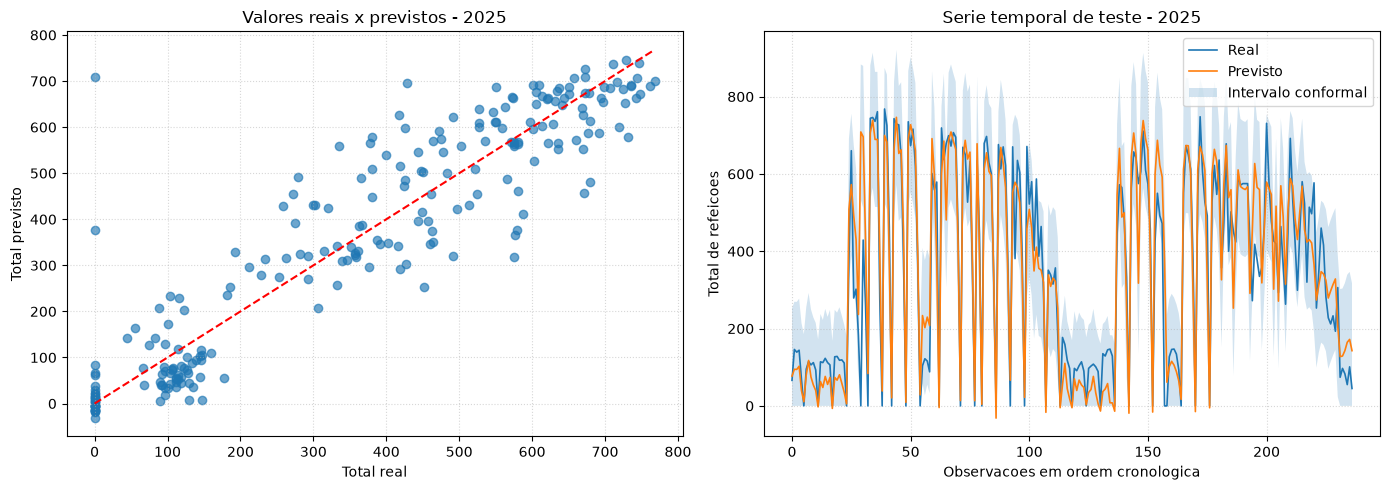

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_teste, previsoes_teste, alpha=0.65)
limite = max(float(y_teste.max()), float(previsoes_teste.max()))
axes[0].plot([0, limite], [0, limite], color="red", linestyle="--")
axes[0].set_title("Valores reais x previstos - 2025")
axes[0].set_xlabel("Total real")
axes[0].set_ylabel("Total previsto")
axes[0].grid(True, linestyle=":", alpha=0.5)

indices = np.arange(len(y_teste))
axes[1].plot(indices, y_teste.to_numpy(), label="Real", linewidth=1.2)
axes[1].plot(indices, previsoes_teste, label="Previsto", linewidth=1.2)
axes[1].fill_between(indices, limite_inferior, limite_superior, alpha=0.2, label="Intervalo conformal")
axes[1].set_title("Serie temporal de teste - 2025")
axes[1].set_xlabel("Observacoes em ordem cronologica")
axes[1].set_ylabel("Total de refeicoes")
axes[1].legend()
axes[1].grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()